In [1]:
from getpass import getuser # Libaray to copy things
from pathlib import Path # Object oriented libary to deal with paths
from dask.utils import format_bytes
from distributed import Client, progress, wait # Libaray to orchestrate distributed resources
#from dask_jobqueue import SLURMCluster # Setting up distributed memories via slurm
import numpy as np # Pythons standard array library
import xarray as xr # Libary to work with labeled n-dimensional data
import dask # Distributed data libary
import dask.distributed
import multiprocessing
from dask.diagnostics import ProgressBar
import glob, os
from matplotlib.lines import Line2D

from matplotlib.patches import Patch
from scipy.ndimage import gaussian_filter1d
from subprocess import run, PIPE
import sys
import os
from sklearn.neighbors import KernelDensity
import gc
from concurrent.futures import ProcessPoolExecutor
import seaborn as sns
import warnings
warnings.filterwarnings(action='ignore')
dask.config.config.get('distributed').get('dashboard').update({'link':'{JUPYTERHUB_SERVICE_PREFIX}/proxy/{port}/status'})
import pandas as pd
from scipy.interpolate import CloughTocher2DInterpolator, LinearNDInterpolator, NearestNDInterpolator

In [2]:
from matplotlib.ticker import (MultipleLocator, FormatStrFormatter, AutoMinorLocator)
from matplotlib import pyplot as plt # Standard Plotting library
from matplotlib import cm
from matplotlib.colors import ListedColormap, LinearSegmentedColormap
from matplotlib.ticker import (MultipleLocator, FormatStrFormatter, AutoMinorLocator)
from cartopy import crs as ccrs # Cartography library
from cartopy.mpl.ticker import LongitudeFormatter, LatitudeFormatter
import cartopy.feature as cfeature
import matplotlib.ticker as mticker
import matplotlib.tri as tri

In [3]:
#'''Provides information about the CPU and starts the dask client'''
ncpu = multiprocessing.cpu_count()
processes = False
nworker = 1
threads = ncpu // nworker
print(f"Number of CPUs: {ncpu}, number of threads: {threads}, number of workers: {nworker}, processes: {processes}")
client = Client(processes=processes,
 threads_per_worker=threads,
 n_workers=nworker,
 memory_limit='1000GB'
 )

Number of CPUs: 64, number of threads: 64, number of workers: 1, processes: False


In [4]:
latitude = [30,60]
mask = '01'      # '1': daily > 1 mm (CMIP6) | '01', '05': hourly > 0.1 / 0.5 mm (CESM2-LE ensemble)

# CMIP6 multi-model distribution, replaces CESM2 when mask == '1' (daily precipitation > 1 mm)
CMIP6_DIR        = '/home/jwille/xenon_data/NextGEMS/mid_lat_precip/CMIP6'   # output of cmip6_precip_cover_calc.py
CMIP6_THRESHOLD  = 1.0           # mm/day
CMIP6_YEARS      = (1850, 2014)  # inclusive
CMIP6_EXCLUDE    = []            # model names to leave out, e.g. ['BCC-CSM2-MR']
CMIP6_MEMBERS_PER_MODEL = 1      # first N members of each model (sorted r, i, p, f); None = all members
# CESM2-LE hourly ensemble, replaces the old CESM2 file when mask == '01' or '05' (hourly precipitation > 0.1 / 0.5 mm)
CESM2_DIR        = '/home/jwille/xenon_data/NextGEMS/mid_lat_precip/cesm2_ens_hourly'   # output of cesm2_hourly_precip_cover_calc.py
CESM2_THRESHOLD  = {'01': 0.1, '05': 0.5}   # mm per hour, for each mask
CESM2_YEARS      = (1850, 2014)  # inclusive

# Grey band: percentiles across the CMIP6 models (mask '1') or the CESM2 members (masks '01', '05')
CMIP6_BAND_RANGE = (10, 90)      # (0, 100) = min-max, (10, 90) = 10-90%

In [5]:
if mask == '1':
    ifs_on = xr.open_dataset('/home/jwille/xenon_data/NextGEMS/mid_lat_precip/cesm2_grid/ifs_2.8km_on_cesm2_grid_1_land_30-60N_precip_count_sum.nc')['dry']
    ifs_off = xr.open_dataset('/home/jwille/xenon_data/NextGEMS/mid_lat_precip/cesm2_grid/ifs_2.8km_off_cesm2_grid_1_land_30-60N_precip_count_sum.nc')['dry']
    ifs_cycle3 = xr.open_dataset('/home/jwille/xenon_data/NextGEMS/mid_lat_precip/cesm2_grid/ifs_cycle3_cesm2_grid_1_land_30-60N_precip_count_sum.nc')['dry']
    ifs_cycle4 = xr.open_dataset('/home/jwille/xenon_data/NextGEMS/mid_lat_precip/cesm2_grid/ifs_cycle4_1990-2019_cesm2_grid_1_land_30-60N_precip_count_sum.nc')['dry']
    icon_cycle3 = xr.open_dataset('/home/jwille/xenon_data/NextGEMS/mid_lat_precip/cesm2_grid/icon_cycle3_cesm2_grid_higher_1_land_30-60N_precip_count_sum.nc')['dry']
    icon_cycle4 = xr.open_dataset('/home/jwille/xenon_data/NextGEMS/mid_lat_precip/cesm2_grid/icon_cycle4_2020-2024_cesm2_grid_higher_1_land_30-60N_precip_count_sum.nc')['dry']
    # CESM2 is replaced by the CMIP6 models (each on its own grid), loaded in the CESM2 / CMIP6 section below
    imerg = xr.open_dataset('/home/jwille/xenon_data/NextGEMS/mid_lat_precip/cesm2_grid/imerg_2014-2023_cesm2_grid_1_land_30-60N_precip_count_sum.nc')['dry']
    #ifs_cycle4 = ifs_cycle4.isel(year=slice(0,30))
    #ifs_cycle4 = ifs_cycle4.stack(sample=("year", "time"))
    #icon_cycle4 = icon_cycle4.isel(year=slice(0,5))
    #icon_cycle4 = icon_cycle4.stack(sample=("year", "time"))
else:
    ifs_on = xr.open_dataset('/home/jwille/xenon_data/NextGEMS/mid_lat_precip/cesm2_grid/ifs_2.8km_on_cesm2_grid_'+mask+'_land_30-60N_precip_count_sum.nc')['dry']
    ifs_off = xr.open_dataset('/home/jwille/xenon_data/NextGEMS/mid_lat_precip/cesm2_grid/ifs_2.8km_off_cesm2_grid_'+mask+'_land_30-60N_precip_count_sum.nc')['dry']
    ifs_cycle3 = xr.open_dataset('/home/jwille/xenon_data/NextGEMS/mid_lat_precip/cesm2_grid/ifs_cycle3_cesm2_grid_'+mask+'_land_30-60N_precip_count_sum.nc')['dry']
    ifs_cycle4 = xr.open_dataset('/home/jwille/xenon_data/NextGEMS/mid_lat_precip/cesm2_grid/ifs_cycle4_1990-2019_cesm2_grid_'+mask+'_land_30-60N_precip_count_sum.nc')['dry']
    #ifs_cycle4_test = xr.open_dataset('/home/jwille/xenon_data/NextGEMS/mid_lat_precip/cesm2_grid/ifs_cycle4_1990-2019_cesm2_grid_higher_'+mask+'_land_30-60N_precip_count_sum.nc')['dry']

    icon_cycle3 = xr.open_dataset('/home/jwille/xenon_data/NextGEMS/mid_lat_precip/cesm2_grid/icon_cycle3_cesm2_grid_higher_'+mask+'_land_30-60N_precip_count_sum.nc')['dry']
    icon_cycle4 = xr.open_dataset('/home/jwille/xenon_data/NextGEMS/mid_lat_precip/cesm2_grid/icon_cycle4_2020-2024_cesm2_grid_higher_'+mask+'_land_30-60N_precip_count_sum.nc')['dry']

    # CESM2: the hourly CESM2-LE ensemble is loaded in the CESM2 / CMIP6 section below
    imerg = xr.open_dataset('/home/jwille/xenon_data/NextGEMS/mid_lat_precip/cesm2_grid/imerg_2014-2023_cesm2_grid_'+mask+'_land_30-60N_precip_count_sum.nc')['dry']


In [6]:
print(ifs_on)

<xarray.DataArray 'dry' (time: 4416)> Size: 35kB
[4416 values with dtype=float64]
Coordinates:
  * time     (time) datetime64[ns] 35kB 2020-05-01 ... 2020-10-31T23:00:00


In [7]:
print(ifs_off)

<xarray.DataArray 'dry' (time: 4416)> Size: 35kB
[4416 values with dtype=float64]
Coordinates:
  * time     (time) datetime64[ns] 35kB 2020-05-01 ... 2020-10-31T23:00:00


In [8]:
cesm2_size = xr.open_dataset('/home/jwille/xenon_data/NextGEMS/CESM2/precip/24H/mask.nc')['MASK']
cesm2_size = cesm2_size[0,:,:]
indexer = ((cesm2_size.lat>=latitude[0]) & (cesm2_size.lat<=latitude[1]))
cesm2_size = cesm2_size.where(indexer,drop=True)
# 5) Compute percentage of grid cells for each time
cesm2_land = xr.where(cesm2_size > 0, 1, 0)
lat_weights = xr.DataArray(
    np.cos(np.deg2rad(cesm2_size['lat'])),
    dims=['lat'],
    coords={'lat': cesm2_size['lat']}
)
total_cells = cesm2_land.weighted(lat_weights).sum()

## IFS on

In [9]:


percent_ifs_on = ifs_on / total_cells * 100  # DataArray of length time
weights_ifs_high = np.ones_like(percent_ifs_on) * 100.0 / percent_ifs_on.size

## IFS off

In [10]:

percent_ifs_off = ifs_off / total_cells * 100  # DataArray of length time


## IFS Cycle3

In [11]:

percent_ifs_cycle3 = ifs_cycle3 / total_cells * 100  # DataArray of length time
weights_ifs_cycle3 = np.ones_like(percent_ifs_cycle3) * 100.0 / percent_ifs_cycle3.size

## IFS Cycle4

In [12]:

percent_ifs_cycle4 = ifs_cycle4 / total_cells * 100  # DataArray of length time
weights_ifs_cycle4 = np.ones_like(percent_ifs_cycle4) * 100.0 / percent_ifs_cycle4.size

In [13]:
print(np.median(percent_ifs_cycle4))

12.566059115700096


## ICON Cycle3

In [14]:

percent_icon_cycle3 = icon_cycle3 / total_cells * 100  # DataArray of length time
weights_icon_cycle3 = np.ones_like(percent_icon_cycle3) * 100.0 / percent_icon_cycle3.size

## ICON Cycle4

In [15]:

percent_icon_cycle4 = icon_cycle4 / total_cells * 100  # DataArray of length time
weights_icon_cycle4 = np.ones_like(percent_icon_cycle4) * 100.0 / percent_icon_cycle4.size

## CESM2 / CMIP6

- **`mask == '1'`** (daily precipitation > 1 mm): the CMIP6 multi-model distribution (each model on its own grid, as CESM2 was). One file per member from `cmip6_precip_cover_calc.py`, first member per model; each model gets the same total weight. The grey band spans the `CMIP6_BAND_RANGE` percentiles of the per-model KDE curves.
- **`mask == '01'` / `'05'`** (hourly precipitation > 0.1 / 0.5 mm): the CESM2-LE historical ensemble (10 members, 1850–2014, May–Oct). One file per member from `cesm2_hourly_precip_cover_calc.py`, with the hourly percentage of land area at 30–60°N above the threshold (cos(lat)-weighted, land = `MASK > 0`). All hours of all members are pooled with equal member weight. The grey band spans the same `CMIP6_BAND_RANGE` percentiles of the per-member KDE curves.

In [16]:
import re
from collections import defaultdict


def weighted_quantile(values, weights, quantiles):
    sorter = np.argsort(values)
    v = np.asarray(values)[sorter]
    cumw = np.cumsum(np.asarray(weights)[sorter])
    cumw /= cumw[-1]
    return np.interp(quantiles, cumw, v)


if mask == '1':
    # CMIP6: daily % of land area with precipitation > CMIP6_THRESHOLD, one file per member
    pat = re.compile(r'^precip_cover_(?P<model>[^_]+)_historical_(?P<member>[^_]+)_30-60N\.nc$')
    member_files = defaultdict(list)
    for f in sorted(os.listdir(CMIP6_DIR)):
        if (m := pat.match(f)) and m['model'] not in CMIP6_EXCLUDE:
            member_files[m['model']].append((m['member'], f))
    # first member(s) of each model, sorted numerically by r, i, p, f (r2 before r10)
    member_files = {model: sorted(mf, key=lambda x: [int(n) for n in re.findall(r'\d+', x[0])])[:CMIP6_MEMBERS_PER_MODEL]
                    for model, mf in member_files.items()}

    cmip6_models = {}   # model -> dict(values = all days of the members used, n_members)
    for model, flist in sorted(member_files.items(), key=lambda kv: kv[0].lower()):
        vals = []
        for _, f in flist:
            da = xr.open_dataset(os.path.join(CMIP6_DIR, f), use_cftime=True)['wet_land_pct']
            da = da.sel(threshold=CMIP6_THRESHOLD, method='nearest')
            if abs(float(da.threshold) - CMIP6_THRESHOLD) > 1e-9:
                raise ValueError(f'{f}: no threshold {CMIP6_THRESHOLD} mm/day')
            yr = da.time.dt.year.values
            vals.append(da.values[(yr >= CMIP6_YEARS[0]) & (yr <= CMIP6_YEARS[1])])
        v = np.concatenate(vals)
        v = v[np.isfinite(v)]
        cmip6_models[model] = dict(values=v, n_members=len(flist))
        print(f'{model:14s} {", ".join(mem for mem, _ in flist)}, {v.size:7d} days, median {np.median(v):5.1f}%')

    # equal model weight: each model's days share 100 / n_models (all weights sum to 100, as for CESM2)
    n_models = len(cmip6_models)
    percent_gcm = xr.DataArray(np.concatenate([d['values'] for d in cmip6_models.values()]), dims='sample')
    weights_gcm = xr.DataArray(np.concatenate([np.full(d['values'].size, 100.0 / n_models / d['values'].size)
                                               for d in cmip6_models.values()]), dims='sample')
    gcm_label = 'CMIP6'
    band_groups, band_kind = {m: d['values'] for m, d in cmip6_models.items()}, 'model'
    print(f'\n{n_models} models, {percent_gcm.size} days in total, {CMIP6_YEARS[0]}-{CMIP6_YEARS[1]}')
else:
    # CESM2-LE: hourly % of land area with precipitation > threshold, one file per member
    thr = CESM2_THRESHOLD[mask]
    pat = re.compile(r'^cesm2_hourly_precip_cover_(?P<member>[^_]+)_30-60N\.nc$')
    cesm2_members = {}   # member -> all hours of that member
    for f in sorted(os.listdir(CESM2_DIR)):
        if not (m := pat.match(f)):
            continue
        da = xr.open_dataset(os.path.join(CESM2_DIR, f), use_cftime=True)['wet_land_pct']
        da = da.sel(threshold=thr, method='nearest')
        if abs(float(da.threshold) - thr) > 1e-9:
            raise ValueError(f'{f}: no threshold {thr} mm/h')
        yr = da.time.dt.year.values
        v = da.values[(yr >= CESM2_YEARS[0]) & (yr <= CESM2_YEARS[1])]
        v = v[np.isfinite(v)]
        cesm2_members[m['member']] = v
        print(f'CESM2 {m["member"]}: {v.size:7d} hours, median {np.median(v):5.1f}%')

    # equal member weight: each member's hours share 100 / n_members (all weights sum to 100)
    n_members = len(cesm2_members)
    percent_gcm = xr.DataArray(np.concatenate(list(cesm2_members.values())), dims='sample')
    weights_gcm = xr.DataArray(np.concatenate([np.full(v.size, 100.0 / n_members / v.size)
                                               for v in cesm2_members.values()]), dims='sample')
    gcm_label = 'CESM2'
    band_groups, band_kind = cesm2_members, 'member'
    print(f'\n{n_members} members, {percent_gcm.size} hours in total, {CESM2_YEARS[0]}-{CESM2_YEARS[1]}, > {thr} mm/h')

band_label = (f'{gcm_label} {band_kind} range' if tuple(CMIP6_BAND_RANGE) == (0, 100)
              else f'{gcm_label} {band_kind}s {CMIP6_BAND_RANGE[0]}-{CMIP6_BAND_RANGE[1]}%')


CESM2 1011.001:  728640 hours, median  15.0%
CESM2 1031.002:  728640 hours, median  15.0%
CESM2 1051.003:  728640 hours, median  15.0%
CESM2 1071.004:  728640 hours, median  14.9%
CESM2 1091.005:  728640 hours, median  15.0%
CESM2 1111.006:  728640 hours, median  14.9%


2026-10-06 16:35:23,537 - distributed.utils_perf - WARNING - full garbage collections took 40% CPU time recently (threshold: 10%)
2026-10-06 16:35:24,334 - distributed.utils_perf - WARNING - full garbage collections took 41% CPU time recently (threshold: 10%)
2026-10-06 16:35:24,955 - distributed.utils_perf - WARNING - full garbage collections took 41% CPU time recently (threshold: 10%)


CESM2 1131.007:  728640 hours, median  15.0%


2026-10-06 16:35:25,918 - distributed.utils_perf - WARNING - full garbage collections took 41% CPU time recently (threshold: 10%)
2026-10-06 16:35:26,549 - distributed.utils_perf - WARNING - full garbage collections took 41% CPU time recently (threshold: 10%)
2026-10-06 16:35:27,354 - distributed.utils_perf - WARNING - full garbage collections took 41% CPU time recently (threshold: 10%)
2026-10-06 16:35:27,995 - distributed.utils_perf - WARNING - full garbage collections took 41% CPU time recently (threshold: 10%)


CESM2 1151.008:  728640 hours, median  15.0%


2026-10-06 16:35:28,977 - distributed.utils_perf - WARNING - full garbage collections took 40% CPU time recently (threshold: 10%)
2026-10-06 16:35:29,638 - distributed.utils_perf - WARNING - full garbage collections took 40% CPU time recently (threshold: 10%)
2026-10-06 16:35:30,457 - distributed.utils_perf - WARNING - full garbage collections took 40% CPU time recently (threshold: 10%)
2026-10-06 16:35:31,130 - distributed.utils_perf - WARNING - full garbage collections took 40% CPU time recently (threshold: 10%)


CESM2 1171.009:  728640 hours, median  14.9%


2026-10-06 16:35:32,181 - distributed.utils_perf - WARNING - full garbage collections took 40% CPU time recently (threshold: 10%)
2026-10-06 16:35:32,889 - distributed.utils_perf - WARNING - full garbage collections took 40% CPU time recently (threshold: 10%)
2026-10-06 16:35:33,767 - distributed.utils_perf - WARNING - full garbage collections took 39% CPU time recently (threshold: 10%)


CESM2 1191.010:  728640 hours, median  14.9%

10 members, 7286400 hours in total, 1850-2014, > 0.1 mm/h


## IMERG

In [17]:
percent_imerg = imerg / total_cells * 100  # DataArray indexed by time
weights_imerg = np.ones_like(percent_imerg) * 100.0 / percent_imerg.size

In [18]:
print(np.median(percent_imerg))

11.118783049595967


In [19]:
# weighted median (equal model weights for CMIP6, equal member weights for CESM2)
print(gcm_label, weighted_quantile(percent_gcm.values, weights_gcm.values, 0.5))

CESM2 14.952447242552525


In [20]:
print(np.median(percent_ifs_off))

12.24337032998698


In [21]:
print(np.median(percent_ifs_on))

13.306832799339134


In [22]:
print(np.median(percent_icon_cycle4))

13.504595320606503


In [23]:
print(np.median(percent_icon_cycle3))

12.582654867451167


In [24]:
print(np.median(percent_ifs_cycle3))

13.12098560312775


In [25]:
print(np.median(percent_ifs_cycle4))

12.566059115700096


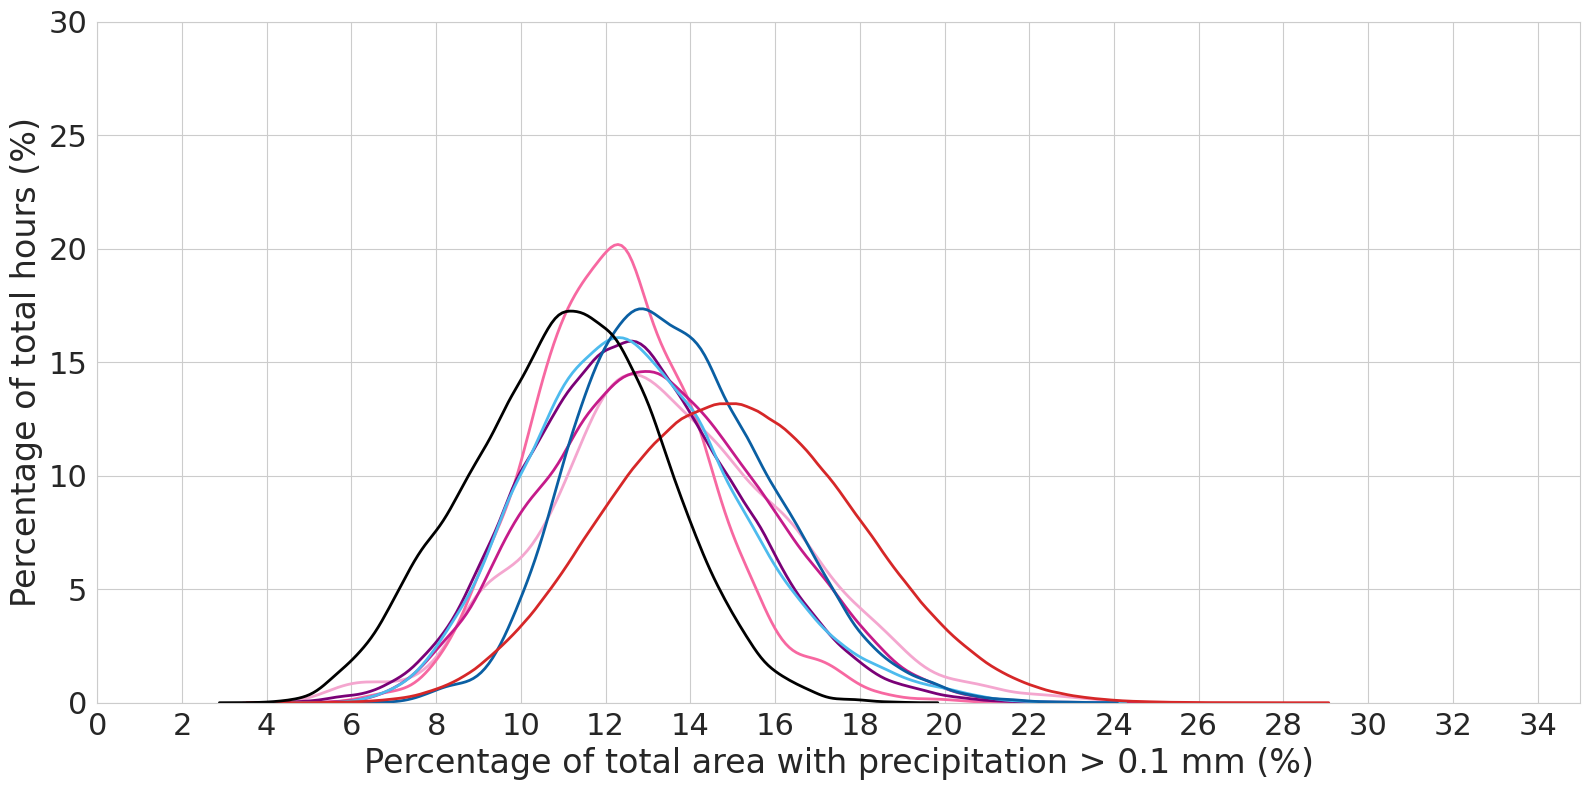

In [26]:
# 1) Common x-range + bin width
if mask == '01':
    xmin, xmax = 0, 35

elif mask == '05':
    xmin, xmax = 0, 25

elif mask == '1':
    xmin, xmax = 10, 50
bin_width  = 1.0
# 2) Your datasets
#datasets = [
#    (percent_ifs_on,    weights,     '#FF8C69', 'IFS_2.8_deep_on'),
#    (percent_ifs_off,   weights,     '#7FFF7F', 'IFS_2.8_deep_off'),
#    (percent_ifs_cycle3,weights,     '#6BB7EC', 'IFS_4.4-FESOM_5'),
#    (percent_ifs_cycle4,weights,     '#FF69B4', 'IFS_9-FESOM_5'),
#    (percent_icon_cycle3,weights,     '#C5A5CF80', 'ICON_5'),
#    (percent_cesm2,     weights_cesm2,'#FFC300','CESM2'),
#    (percent_imerg,     weights,     '#7E57C2', 'IMERG'),
#]


#datasets = [
    # IFS group – improved contrast (warm & distinct)
#    (percent_ifs_on,     weights_ifs_high,    '#D73027', 'IFS_2.8_deep_on'),   # deep red
#    (percent_ifs_off,    weights_ifs_high,    '#FC8D59', 'IFS_2.8_deep_off'),  # coral/orange
#    (percent_ifs_cycle3, weights_ifs_cycle3,  '#91BFDB', 'IFS_4.4-FESOM_5'),   # sky blue
#    (percent_ifs_cycle4, weights_ifs_cycle4,  '#4575B4', 'IFS_9-FESOM_5'),     # strong blue

    # ICON group – cohesive purples
#    (percent_icon_cycle3, weights_icon_cycle3, '#9467BD', 'ICON_5'),           # medium purple
#    (percent_icon_cycle4, weights_icon_cycle4, '#C5B0D5', 'ICON_9'),           # soft lilac

    # CESM2 – distinct highlight (gold)
#    (percent_cesm2,      weights_cesm2,       '#E6AB02', 'CESM2'),

    # IMERG – distinct but not pure black (deep violet)
#    (percent_imerg,      weights_imerg,       'k', 'IMERG'),
#]

datasets = [
    # IFS group – range of magentas (light → dark)
    (percent_ifs_on,     weights_ifs_high,    '#F4A6CF', 'IFS_2.8_deep_on'),   # pale pink-magenta
    (percent_ifs_off,    weights_ifs_high,    '#F768A1', 'IFS_2.8_deep_off'),  # mid magenta
    (percent_ifs_cycle3, weights_ifs_cycle3,  '#C51B8A', 'IFS_4.4-FESOM_5'),   # strong magenta
    (percent_ifs_cycle4, weights_ifs_cycle4,  '#7A0177', 'IFS_9-FESOM_5'),     # deep magenta
    # ICON group – range of blues (light → dark)
    (percent_icon_cycle3, weights_icon_cycle3, '#4DBBEE', 'ICON_5'),           # sky blue
    (percent_icon_cycle4, weights_icon_cycle4, '#0A5FA3', 'ICON_9'),           # deep blue
    # CMIP6 multi-model (mask '1') or CESM2-LE ensemble (masks '01', '05') – red
    (percent_gcm,        weights_gcm,         '#D62728', gcm_label),
    # IMERG – black
    (percent_imerg,      weights_imerg,       '#000000', 'IMERG'),
]



plt.figure(figsize=(16, 8))
sns.set_style("whitegrid")
plt.rc('axes', titlesize=22)
plt.rc('axes', labelsize=18)

# 3) Plot only the KDEs
for data_da, wts_da, color, label in datasets:
    # extract numpy
    x = data_da.values.ravel()
    w = wts_da.values.ravel() if hasattr(wts_da, 'values') else np.asarray(wts_da).ravel()
    # drop NaNs
    #mask_plot = ~np.isnan(x)
    #x, w = x[mask_plot], w[mask_plot]
    #print(label)
    #print(len(x))
    # normalize weights so area under curve = 1
    #w_norm = w 
  
    sns.kdeplot(
        x=x,
        weights=w,
        bw_adjust=1.0,      # tweak for smoother / sharper
        clip=(xmin, xmax),
        common_norm=False,  # each curve normalizes to its own w_norm
        fill=False,
        linewidth=2.0,
        color=color,
        label=label
    )

# 4) Rescale each line from density → percent per 0.5% bin
ax = plt.gca()
for line in ax.get_lines():
    x_vals, y_vals = line.get_data()
    y_scaled = y_vals * 100 * bin_width
    line.set_data(x_vals, y_scaled)

# 4b) Grey band: CMIP6_BAND_RANGE percentiles of the per-model (CMIP6) or per-member (CESM2) KDE curves
#     (Scott bandwidth of each one's own sample), evaluated on the same x values as the CMIP6 / CESM2 line
if band_groups and mask == '1':     # grey band only for the CMIP6 models (mask '1')
    from scipy.stats import gaussian_kde
    gcm_line = ax.get_lines()[[lab for *_, lab in datasets].index(gcm_label)]
    x_grid = gcm_line.get_xdata()
    model_curves = np.array([gaussian_kde(v)(x_grid) * 100 * bin_width for v in band_groups.values()])
    band_lo, band_hi = np.percentile(model_curves, CMIP6_BAND_RANGE, axis=0)
    ax.fill_between(x_grid, band_lo, band_hi, color='#888888', alpha=0.15, linewidth=0, zorder=0)

# 5) Labels, limits, legend
if mask == '01':
    xl = 'Percentage of total area with precipitation > 0.1 mm (%)'
    ax.set_ylim(0, 30)
elif mask == '05':
    xl = 'Percentage of total area with precipitation > 0.5 mm (%)'
    ax.set_ylim(0, 70)
    # Force y-ticks to be whole numbers, and reduce their number by half
    #ymin, ymax = ax.get_ylim()
    #yticks = np.arange(ymin, ymax + 1, 4)  # step=2 gives roughly half as many ticks
    #ax.set_yticks(yticks)
    #ax.set_yticklabels([f'{int(y)}' for y in yticks])  # ensures no decimals

elif mask == '1':
    xl = 'Percentage of total area with precipitation > 1 mm (%)'
    ax.set_ylim(0, 18)

plt.xlabel(xl, fontsize=24)
if mask == '1':
    plt.ylabel('Percentage of total days (%)', fontsize=24)
else:
    plt.ylabel('Percentage of total hours (%)', fontsize=24)

plt.xlim(xmin, xmax)
plt.tick_params(axis='both', which='major', labelsize=22)

xticks = np.arange(xmin, xmax, 2)
ax.set_xticks(xticks)

# build a list of Line2D handles matching your plotted lines
legend_handles = [
    Line2D([0], [0], color=color, linewidth=2.0)
    for *_, color, _ in datasets
]
# extract the labels out of your datasets tuple
legend_labels = [label for *_, _, label in datasets]
if band_groups and mask == '1':     # grey band only for the CMIP6 models (mask '1')
    legend_handles.append(Patch(facecolor='#888888', alpha=0.15, edgecolor='none'))
    legend_labels.append(band_label)

# then call legend with those handles
#plt.legend(
#    legend_handles,
#    legend_labels,
#    loc='upper right',
#    prop={'size': 22},
#    bbox_to_anchor=(1.0, 1.0),
#    handlelength=2.5  # longer lines in legend if you like
#)

plt.tight_layout()
plt.savefig('/home/jwille/images/global_paper/mid_lat_land_cesm2_grid_histo_precip_coverage_'+mask+'_new'
            +('_CMIP6mmm' if gcm_label == 'CMIP6' else '_CESM2ens')+'.pdf', format='pdf',bbox_inches='tight')

plt.show()